# Shooting Method for the Blasius Boundary-Layer Equation
**AE801 – Scientific Computing, Lab 1**

**Name:** Bala Surya S  
**Roll No.:** SC26M009 
---

## 1. What problem are we solving?

Imagine a uniform stream of air (speed $U_\infty$) flowing over a thin flat plate. Right at the plate surface the air sticks to it (no-slip), so its speed is zero. Far away from the plate the air moves at the free-stream speed $U_\infty$. In between there is a thin layer where the speed rises smoothly from $0$ to $U_\infty$ – this is the **boundary layer**.

Using the similarity variable

$$\eta = y\sqrt{\frac{U_\infty}{\nu x}}, \qquad \frac{u}{U_\infty} = f'(\eta),$$

the governing PDEs collapse into one ordinary differential equation, the **Blasius equation**:

$$f''' + \frac12\, f\, f'' = 0, \qquad 0<\eta<\infty$$

with boundary conditions

| Condition | Meaning |
|---|---|
| $f(0)=0$ | no suction/blowing through the plate |
| $f'(0)=0$ | no-slip: velocity is zero at the wall |
| $f'(\eta)\to 1$ as $\eta\to\infty$ | velocity reaches the free stream far from the wall |

## 2. Why is this difficult?

It is a **boundary value problem (BVP)**: the conditions are given at *two different places* ($\eta=0$ and $\eta=\infty$). A normal ODE solver (like Runge–Kutta) needs *all* conditions at the **starting point**. Here we only know two of the three we need at $\eta=0$: we know $f(0)$ and $f'(0)$, but **not** $f''(0)$.

## 3. The idea of the shooting method (in simple words)

Think of firing a cannon at a target:

1. **Guess** the missing initial condition – call it $s = f''(0)$ (this is the "angle of the cannon").
2. **Integrate** the ODE from $\eta=0$ out to a large $\eta_\infty$ (this is the "flight of the cannonball").
3. **Check** how far we missed the target: the residual $F(s) = f'(\eta_\infty; s) - 1$.
4. **Adjust the guess** using a root finder (secant method) and repeat until $F(s)\approx 0$.

When $F(s)=0$, our solution satisfies the far-field condition, so it solves the original BVP.

## 4. Plan of this notebook

| Step | What we do |
|---|---|
| (a) | Convert the 3rd-order ODE to a first-order system and build RK3 / RK4 solvers |
| (b),(c) | Define the shooting parameter and residual, solve with the secant method |
| (d) | Run RK3 on five step sizes and check its order of accuracy (log–log plot) |
| (e) | Plot $f$, $f'$, $f''$ against $\eta$ |
| (f) | Repeat (d) and (e) with RK4 |
| (g) | Verify $f''(0)\approx 0.332$ |

## 5. Setup

We use `numpy` for arrays and `matplotlib` for plots.

**Choice of $\eta_\infty$.** We cannot integrate to a true infinity, so we pick a large finite value. The Blasius solution approaches the free stream very quickly (by $\eta\approx 5$ the velocity is already 99% of $U_\infty$), so $\eta_\infty = 10$ is safely "far enough". Later in this notebook we test this choice by varying $\eta_\infty$.

`S_REF` is the well-known literature value of $f''(0)$. We use it **only** to measure errors in the plots; the solver itself never sees it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

ETA_INF = 10.0          
TOL     = 1e-12              
S_REF   = 0.33205733621519   

print("eta_inf  =", ETA_INF)
print("tolerance =", TOL)
print("reference f''(0) =", S_REF)

eta_inf  = 10.0
tolerance = 1e-12
reference f''(0) = 0.33205733621519


## Step (a): Convert the ODE into a first-order system

Runge–Kutta methods solve **first-order** systems $Y' = G(Y)$. Our equation is third order, so we introduce three unknowns:

$$Y=\begin{pmatrix} f\\ f'\\ f''\end{pmatrix}
\quad\Longrightarrow\quad
Y' = G(Y)=\begin{pmatrix} f'\\ f''\\ -\tfrac12 f f''\end{pmatrix}$$

* first entry: derivative of $f$ is $f'$ (already part of $Y$),
* second entry: derivative of $f'$ is $f''$ (already part of $Y$),
* third entry: derivative of $f''$ is $f'''$, which the Blasius equation says equals $-\tfrac12 f f''$.

The function `G` below simply returns this right-hand side.

In [2]:
def G(Y):
    f, fp, fpp = Y
    return np.array([fp,fpp,-0.5 * f * fpp])  

Y_test = np.array([1.0, 2.0, 3.0])
print("Y        =", Y_test)
print("G(Y)     =", G(Y_test), "  (expected [2, 3, -1.5])")

Y        = [1. 2. 3.]
G(Y)     = [ 2.   3.  -1.5]   (expected [2, 3, -1.5])


## Runge–Kutta methods (RK3 and RK4)

To move from $\eta_n$ to $\eta_{n+1}=\eta_n+\Delta\eta$, an RK method evaluates the slope $G$ at several intermediate points ("stages" $k_i$) and combines them in a weighted average.

**RK3** (Kutta's third-order method, 3 stages):
$$k_1=G(Y_n),\quad k_2=G\!\left(Y_n+\tfrac{\Delta\eta}{2}k_1\right),\quad k_3=G\!\left(Y_n-\Delta\eta\,k_1+2\Delta\eta\,k_2\right)$$
$$Y_{n+1}=Y_n+\frac{\Delta\eta}{6}\left(k_1+4k_2+k_3\right)$$

**RK4** (classical fourth-order method, 4 stages):
$$k_1=G(Y_n),\; k_2=G\!\left(Y_n+\tfrac{\Delta\eta}{2}k_1\right),\; k_3=G\!\left(Y_n+\tfrac{\Delta\eta}{2}k_2\right),\; k_4=G(Y_n+\Delta\eta\,k_3)$$
$$Y_{n+1}=Y_n+\frac{\Delta\eta}{6}\left(k_1+2k_2+2k_3+k_4\right)$$

**Expected accuracy:** RK3 has a global error $\propto \Delta\eta^{3}$, RK4 has $\propto\Delta\eta^{4}$. Halving the step should reduce the error by about $2^3=8$ (RK3) or $2^4=16$ (RK4).

**How the code is organised.** Instead of typing the two formulas separately, we store each method as a small table of numbers (a *Butcher tableau*): the matrix `A` says which earlier stages feed into each new stage, and the vector `b` gives the final weights. One general function `rk_step` then works for *both* methods.

In [3]:
TABLEAU = {
    "RK3": (np.array([[ 0.0, 0.0, 0.0],
                      [ 0.5, 0.0, 0.0],
                      [-1.0, 2.0, 0.0]]),
            np.array([1/6, 4/6, 1/6])),

    "RK4": (np.array([[0.0, 0.0, 0.0, 0.0],
                      [0.5, 0.0, 0.0, 0.0],
                      [0.0, 0.5, 0.0, 0.0],
                      [0.0, 0.0, 1.0, 0.0]]),
            np.array([1/6, 2/6, 2/6, 1/6])),
}

def rk_step(func, Y, h, A, b):
    stages = len(b)
    k = []                                   
    for i in range(stages):
        Y_stage = Y.copy()
        for j in range(i):
            Y_stage = Y_stage + h * A[i, j] * k[j]
        k.append(func(Y_stage)) 
    Y_new = Y.copy()
    for i in range(stages):
        Y_new = Y_new + h * b[i] * k[i]
    return Y_new

print("RK3 weights sum to", TABLEAU["RK3"][1].sum(), "| RK4 weights sum to", TABLEAU["RK4"][1].sum(), "(both must be 1)")

RK3 weights sum to 0.9999999999999999 | RK4 weights sum to 0.9999999999999999 (both must be 1)


### Sanity test of the RK code (before using it on Blasius)

It is good practice to test a new solver on a problem whose exact answer we know. Take $y'=-y$, $y(0)=1$, whose exact solution is $e^{-t}$. We solve to $t=1$ with different step sizes and compute the observed order of accuracy

$$p \approx \log_2\frac{\text{error}(h)}{\text{error}(h/2)}.$$

If our RK3 and RK4 are programmed correctly, we should see $p\approx 3$ and $p\approx 4$.

In [4]:
def decay(Y):                 
    return -Y

print(f"{'method':>6} {'h':>8} {'error at t=1':>16} {'observed order':>16}")
for name in ("RK3", "RK4"):
    A, b = TABLEAU[name]
    prev_err = None
    for h in [0.2, 0.1, 0.05, 0.025]:
        n = int(round(1.0 / h))
        y = np.array([1.0])
        for _ in range(n):
            y = rk_step(decay, y, h, A, b)
        err = abs(y[0] - np.exp(-1.0))
        order = "" if prev_err is None else f"{np.log2(prev_err/err):.3f}"
        print(f"{name:>6} {h:8.3f} {err:16.4e} {order:>16}")
        prev_err = err
    print()

method        h     error at t=1   observed order
   RK3    0.200       1.4396e-04                 
   RK3    0.100       1.6607e-05            3.116
   RK3    0.050       1.9943e-06            3.058
   RK3    0.025       2.4435e-07            3.029

   RK4    0.200       5.7970e-06                 
   RK4    0.100       3.3324e-07            4.121
   RK4    0.050       1.9976e-08            4.060
   RK4    0.025       1.2227e-09            4.030



The observed orders are very close to 3 and 4, so the RK stepper is working correctly.

### Integrating from $\eta=0$ to $\eta_\infty$

`integrate(s, h, method)` starts at the known initial values $Y(0)=(0,0,s)$ and repeatedly calls `rk_step` until it reaches $\eta_\infty$. It can either return only the final state (fast, used inside the root finder) or the whole solution (used for plotting).

In [5]:
def integrate(s, h, method, return_all=False):
    A, b = TABLEAU[method]
    n = int(round(ETA_INF / h))
    Y = np.array([0.0, 0.0, s])
    if return_all:
        history = np.zeros((n + 1, 3))
        history[0] = Y
    for i in range(n):
        Y = rk_step(G, Y, h, A, b)
        if return_all:
            history[i + 1] = Y
    return history if return_all else Y


Y_end = integrate(0.3, 0.05, "RK4")
print("Shot with s = 0.3  ->  at eta = 10:  f = %.5f,  f' = %.5f,  f'' = %.5f" % tuple(Y_end))
print("We wanted f' = 1, so this guess misses the target.")

Shot with s = 0.3  ->  at eta = 10:  f = 7.68203,  f' = 0.93456,  f'' = 0.00000
We wanted f' = 1, so this guess misses the target.


## Steps (b) and (c): shooting parameter, residual and root finding

**Missing initial condition.** We know $f(0)=0$ and $f'(0)=0$, so the unknown is
$$s = f''(0).$$

**Residual.** For each guess $s$ we integrate to $\eta_\infty$ and measure the miss:
$$F(s;\eta_\infty) = f'(\eta_\infty;\,s) - 1.$$
The true $s$ is the **root** of $F$ (i.e. $F(s)=0$).

### Looking at the residual first
Before using a root finder, let us just *look* at $F(s)$ for several guesses. If $F$ changes sign between two values of $s$, the root lies between them. This also helps us pick sensible starting guesses.

 s guess   f(eta_inf)   f'(eta_inf)   residual F(s)   comment
    0.10       3.3395       0.44921    -5.50792e-01   undershoot (f' < 1)
    0.20       5.6788       0.71320    -2.86801e-01   undershoot (f' < 1)
    0.30       7.6820       0.93456    -6.54438e-02   undershoot (f' < 1)
    0.33       8.2414       0.99587    -4.13476e-03   undershoot (f' < 1)
    0.34       8.4244       1.01588     1.58835e-02   overshoot (f' > 1)
    0.40       9.4904       1.13213     1.32134e-01   overshoot (f' > 1)
    0.50      11.1649       1.31373     3.13725e-01   overshoot (f' > 1)
    0.60      12.7392       1.48352     4.83516e-01   overshoot (f' > 1)


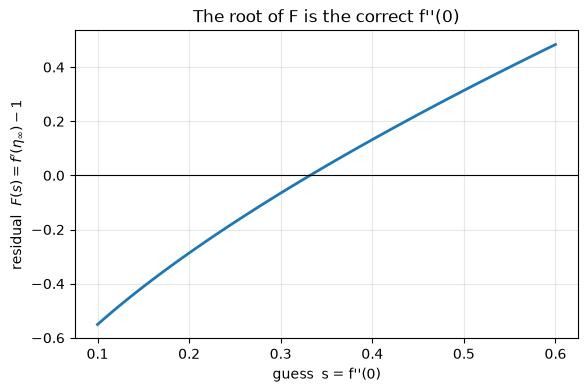

In [6]:
print("{:>8} {:>12} {:>13} {:>15}   comment".format("s guess", "f(eta_inf)", "f'(eta_inf)", "residual F(s)"))
for s in [0.10, 0.20, 0.30, 0.33, 0.34, 0.40, 0.50, 0.60]:
    Y_end = integrate(s, 0.05, "RK4")
    F = Y_end[1] - 1.0
    comment = "undershoot (f' < 1)" if F < 0 else "overshoot (f' > 1)"
    print(f"{s:8.2f} {Y_end[0]:12.4f} {Y_end[1]:13.5f} {F:15.5e}   {comment}")

# plot the residual as a function of s
s_vals = np.linspace(0.1, 0.6, 60)
F_vals = [integrate(s, 0.05, "RK4")[1] - 1.0 for s in s_vals]
plt.figure(figsize=(6.5, 4))
plt.plot(s_vals, F_vals, lw=2)
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("guess  s = f''(0)")
plt.ylabel(r"residual  $F(s)=f'(\eta_\infty)-1$")
plt.title("The root of F is the correct f''(0)")
plt.grid(alpha=0.3); plt.show()

The curve is smooth and crosses zero near $s\approx0.33$, with exactly one crossing. So a simple root finder will work.

### Secant method

The secant method needs two starting guesses $s_0, s_1$ and then repeats

$$s_{k+1}=s_k-F(s_k)\,\frac{s_k-s_{k-1}}{F(s_k)-F(s_{k-1})}.$$

In words: draw a straight line through the last two points $(s_{k-1},F_{k-1})$ and $(s_k,F_k)$ and jump to where this line crosses zero. It is like Newton's method but does not need the derivative $dF/ds$ (which would be awkward to compute here). We stop when two successive guesses differ by less than `TOL`.

Setting `verbose=True` prints every iteration so we can watch it converge.

In [7]:
def secant(h, method, s0=0.2, s1=0.5, tol=TOL, itmax=60, verbose=False):
    F0 = integrate(s0, h, method)[1] - 1.0
    F1 = integrate(s1, h, method)[1] - 1.0
    if verbose:
        print(f"{'iter':>4} {'s':>18} {'F(s)':>14} {'|s_new - s_old|':>16}")
        print(f"{0:>4} {s0:18.12f} {F0:14.4e} {'-':>16}")
        print(f"{1:>4} {s1:18.12f} {F1:14.4e} {abs(s1-s0):16.4e}")
    for it in range(1, itmax + 1):
        s2 = s1 - F1 * (s1 - s0) / (F1 - F0)         
        F2 = integrate(s2, h, method)[1] - 1.0
        change = abs(s2 - s1)
        if verbose:
            print(f"{it+1:>4} {s2:18.12f} {F2:14.4e} {change:16.4e}")
        s0, F0, s1, F1 = s1, F1, s2, F2               
        if change < tol:
            return s1, it
    raise RuntimeError("Secant method did not converge")

print("Secant history for RK4, step size 0.05, starting guesses 0.2 and 0.5:\n")
s_demo, its_demo = secant(0.05, "RK4", verbose=True)
print(f"\nConverged: f''(0) = {s_demo:.12f}  after {its_demo} secant steps")

Secant history for RK4, step size 0.05, starting guesses 0.2 and 0.5:

iter                  s           F(s)  |s_new - s_old|
   0     0.200000000000    -2.8680e-01                -
   1     0.500000000000     3.1373e-01       3.0000e-01
   2     0.343274703421     2.2396e-02       1.5673e-01
   3     0.331226414192    -1.6689e-03       1.2048e-02
   4     0.332061976106     9.3123e-06       8.3556e-04
   5     0.332057339693     3.8865e-09       4.6364e-06
   6     0.332057337757    -8.7708e-15       1.9358e-09
   7     0.332057337757    -5.5511e-16       4.3854e-15

Converged: f''(0) = 0.332057337757  after 6 secant steps


Notice how the residual $F(s)$ drops from about $10^{-1}$ to roughly $10^{-15}$ in just a handful of iterations, and the change in $s$ shrinks super-linearly. That is the fast convergence typical of the secant method.

## Step (d): RK3 with $\Delta\eta = 0.4,\,0.2,\,0.1,\,0.05,\,0.025$

For every step size we run the full shooting procedure and record:

* **N steps** – number of RK steps to reach $\eta_\infty$,
* **$f''(0)$** – the computed shooting parameter,
* **error** – $|s-s_{ref}|$,
* **$f'(\eta_\infty)$** – should be 1 (a check that the far-field condition is met),
* **error ratio** – error at previous (coarser) $h$ divided by the current error. For a method of order $p$ this ratio should be near $2^p$,
* **observed order** – $\log_2$ of the error ratio.

Two ways to measure the order are printed:
1. using the **error vs the literature value** (`order vs ref`), and
2. using **differences between consecutive solutions** (`order (self)`), which does not need the exact value at all.

In [8]:
steps = [0.4, 0.2, 0.1, 0.05, 0.025]
results = {}                            

def run_study(method):
    print("=" * 108)
    print(f"  SHOOTING METHOD with {method},  eta_inf = {ETA_INF}")
    print("=" * 108)
    print("{:>7} {:>8} {:>16} {:>14} {:>14} {:>6} {:>10} {:>13} {:>13}".format(
          "d_eta", "N steps", "f''(0) = s", "error |s-ref|", "f'(eta_inf)",
          "iters", "err ratio", "order vs ref", "order (self)"))
    S, E = [], []
    for h in steps:
        s, its = secant(h, method)
        fp_end = integrate(s, h, method)[1]
        S.append(s); E.append(abs(s - S_REF))
        ratio = "" if len(E) < 2 else f"{E[-2]/E[-1]:.2f}"
        ord_ref = "" if len(E) < 2 else f"{np.log2(E[-2]/E[-1]):.2f}"
        ord_self = ""
        if len(S) >= 3:
            ord_self = f"{np.log2(abs(S[-2]-S[-3]) / abs(S[-1]-S[-2])):.2f}"
        print(f"{h:7.3f} {int(round(ETA_INF/h)):8d} {s:16.10f} {E[-1]:14.3e} {fp_end:14.10f} "
              f"{its:6d} {ratio:>10} {ord_ref:>13} {ord_self:>13}")
    print("-" * 108)
    print(f"Final answer ({method}, finest grid): f''(0) = {S[-1]:.6f}")
    print(f"Expected value                       : f''(0) = 0.332 ... -> agrees to 3 digits: {round(S[-1],3) == 0.332}")
    results[method] = (np.array(S), np.array(E))

run_study("RK3")

  SHOOTING METHOD with RK3,  eta_inf = 10.0
  d_eta  N steps       f''(0) = s  error |s-ref|    f'(eta_inf)  iters  err ratio  order vs ref  order (self)
  0.400       25     0.3319771448      8.019e-05   1.0000000000      6                                       
  0.200       50     0.3320495982      7.738e-06   1.0000000000      6      10.36          3.37              
  0.100      100     0.3320565334      8.028e-07   1.0000000000      6       9.64          3.27          3.39
  0.050      200     0.3320572476      8.862e-08   1.0000000000      6       9.06          3.18          3.28
  0.025      400     0.3320573267      9.514e-09   1.0000000000      6       9.31          3.22          3.17
------------------------------------------------------------------------------------------------------------
Final answer (RK3, finest grid): f''(0) = 0.332057
Expected value                       : f''(0) = 0.332 ... -> agrees to 3 digits: True


**Reading the table.** The error ratio for RK3 is around 8–10 and the observed order is about 3. That matches the theory (error $\propto \Delta\eta^3$). The column $f'(\eta_\infty)$ equals 1 to ten digits: the secant solver really drove the residual to zero. Every step size needed only about 6 secant iterations.

## Step (f): repeat with RK4

In [9]:
run_study("RK4")

  SHOOTING METHOD with RK4,  eta_inf = 10.0
  d_eta  N steps       f''(0) = s  error |s-ref|    f'(eta_inf)  iters  err ratio  order vs ref  order (self)
  0.400       25     0.3320588158      1.480e-06   1.0000000000      6                                       
  0.200       50     0.3320574575      1.212e-07   1.0000000000      6      12.20          3.61              
  0.100      100     0.3320573456      9.395e-09   1.0000000000      6      12.90          3.69          3.60
  0.050      200     0.3320573378      1.542e-09   1.0000000000      6       6.09          2.61          3.83
  0.025      400     0.3320573372      1.024e-09   1.0000000000      6       1.51          0.59          3.92
------------------------------------------------------------------------------------------------------------
Final answer (RK4, finest grid): f''(0) = 0.332057
Expected value                       : f''(0) = 0.332 ... -> agrees to 3 digits: True


**Reading the table.** For RK4 the first ratios are about 12–13 (order about 3.6–3.7 against the reference), and the self-comparison order climbs 3.60, 3.83, 3.92 towards 4, as expected. At the two finest steps the error against the reference stops shrinking (ratios 6.1 and 1.5). That is **not** a bug in RK4: with such a small step the RK error becomes smaller than a *different* error – the error from stopping at $\eta_\infty=10$ instead of infinity. We prove this in the next section.

## Why does RK4 flatten out? Testing the choice of $\eta_\infty$

If the plateau is due to truncating the domain, then changing $\eta_\infty$ should change the answer at the $10^{-9}$ level. We keep RK4 and $\Delta\eta=0.025$ fixed and vary $\eta_\infty$.

In [10]:
print("{:>8} {:>18} {:>16}".format("eta_inf", "f''(0)", "error |s-ref|"))
ETA_SAVE = ETA_INF
for eta_inf in [4, 6, 8, 10, 12]:
    ETA_INF = float(eta_inf)             
    s, _ = secant(0.025, "RK4")
    print(f"{eta_inf:8d} {s:18.12f} {abs(s - S_REF):16.3e}")
ETA_INF = ETA_SAVE                        
print("\nrestored eta_inf =", ETA_INF)

 eta_inf             f''(0)    error |s-ref|
       4     0.352746253590        2.069e-02
       6     0.332565931295        5.086e-04
       8     0.332059191772        1.856e-06
      10     0.332057337239        1.024e-09
      12     0.332057336251        3.555e-11

restored eta_inf = 10.0


The error drops quickly as $\eta_\infty$ increases (the solution approaches 1 exponentially fast), confirming that the floor at about $10^{-9}$ comes from the finite $\eta_\infty=10$, not from the RK4 scheme. For this lab $\eta_\infty=10$ is more than good enough: the answer is correct to 8 digits.

## Log–log convergence plot

On a log–log plot, a method of order $p$ appears as a **straight line with slope $p$**. The dashed and dotted black lines show slopes 3 and 4 for comparison. We also print the least-squares slope of the data.

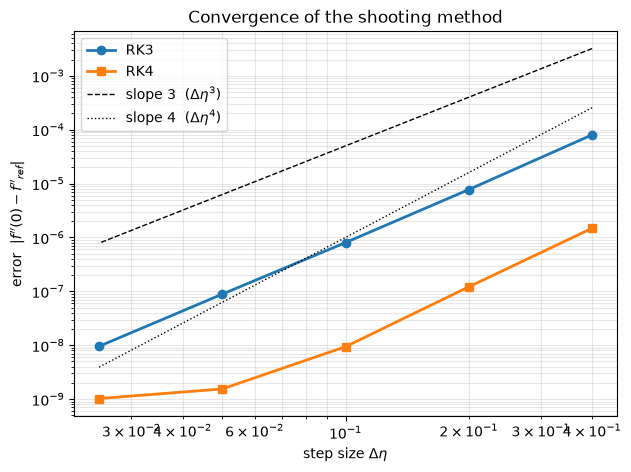

RK3: least-squares slope of the log-log line (4 coarsest steps) = 3.27
RK4: least-squares slope of the log-log line (4 coarsest steps) = 3.34


In [11]:
hs = np.array(steps)

plt.figure(figsize=(7, 5))
plt.loglog(hs, results["RK3"][1], "o-", lw=2, label="RK3")
plt.loglog(hs, results["RK4"][1], "s-", lw=2, label="RK4")
plt.loglog(hs, 0.05 * hs**3, "k--", lw=1, label=r"slope 3  ($\Delta\eta^3$)")
plt.loglog(hs, 0.01 * hs**4, "k:",  lw=1, label=r"slope 4  ($\Delta\eta^4$)")
plt.xlabel(r"step size $\Delta\eta$")
plt.ylabel(r"error  $|f''(0) - f''_{ref}|$")
plt.title("Convergence of the shooting method")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

for m in ("RK3", "RK4"):
    slope = np.polyfit(np.log(hs[:4]), np.log(results[m][1][:4]), 1)[0]
    print(f"{m}: least-squares slope of the log-log line (4 coarsest steps) = {slope:.2f}")

The **RK4 line lies below RK3** (smaller error at the same step size) and is steeper at coarse steps. Both are close to their theoretical slopes (3 and 4). The fitted RK4 slope (about 3.3) is pulled down because the RK4 curve bends at small $\Delta\eta$ due to the $\eta_\infty$ floor explained above; the self-comparison order (3.6 → 3.9) shows the true trend.

## Step (e): profiles of $f$, $f'$ and $f''$ (and again for RK4)

With the converged $s$ we integrate once more, this time keeping the full solution, and plot it:

* $f(\eta)$ – the stream function,
* $f'(\eta)=u/U_\infty$ – the **velocity profile**; rises from 0 at the wall to 1 in the free stream,
* $f''(\eta)$ – proportional to the shear stress; largest at the wall ($=s$) and decays to 0.

The plots are drawn for $\Delta\eta=0.025$.

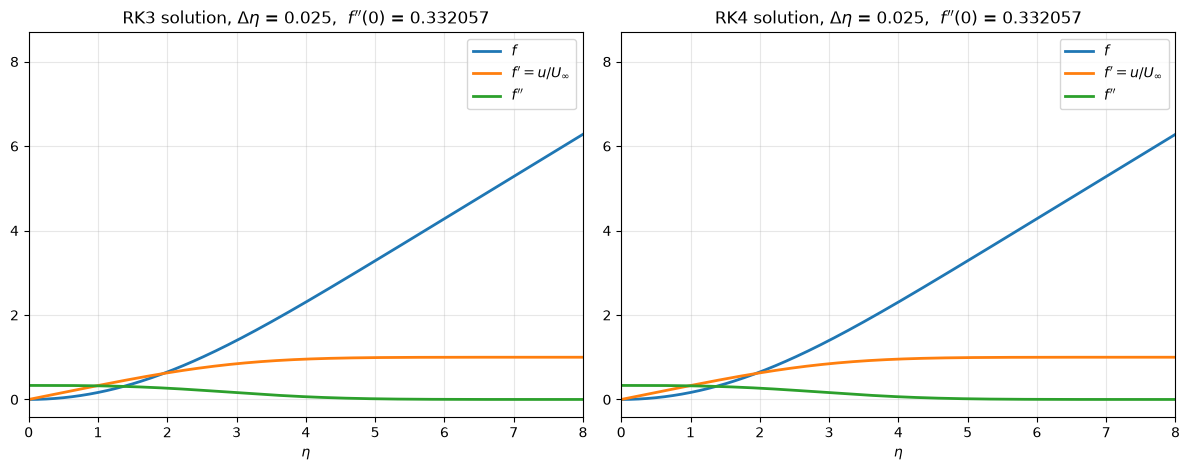

In [12]:
h_plot = 0.025
profiles = {}
for m in ("RK3", "RK4"):
    s, _ = secant(h_plot, m)
    sol = integrate(s, h_plot, m, return_all=True)
    eta = np.linspace(0, ETA_INF, len(sol))
    profiles[m] = (eta, sol, s)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, m in zip(axes, ("RK3", "RK4")):
    eta, sol, s = profiles[m]
    ax.plot(eta, sol[:, 0], lw=2, label=r"$f$")
    ax.plot(eta, sol[:, 1], lw=2, label=r"$f' = u/U_\infty$")
    ax.plot(eta, sol[:, 2], lw=2, label=r"$f''$")
    ax.set_xlim(0, 8)
    ax.set_xlabel(r"$\eta$")
    ax.set_title(f"{m} solution, $\\Delta\\eta$ = {h_plot},  $f''(0)$ = {s:.6f}")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### Numerical values at selected points

A table gives exact numbers behind the curves. The two methods should agree to many digits; the last column shows their difference.

In [13]:
eta_RK3, sol_RK3, _ = profiles["RK3"]
eta_RK4, sol_RK4, _ = profiles["RK4"]

print("{:>5} | {:>10} {:>10} {:>10} | {:>30}".format("eta", "f (RK4)", "f' (RK4)", "f'' (RK4)", "max |RK3-RK4| over f,f',f''"))
print("-" * 78)
for target in [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10]:
    i = int(round(target / h_plot))
    diff = np.max(np.abs(sol_RK3[i] - sol_RK4[i]))
    print(f"{eta_RK4[i]:5.1f} | {sol_RK4[i,0]:10.6f} {sol_RK4[i,1]:10.6f} {sol_RK4[i,2]:10.6f} | {diff:30.3e}")

  eta |    f (RK4)   f' (RK4)  f'' (RK4) |    max |RK3-RK4| over f,f',f''
------------------------------------------------------------------------------
  0.0 |   0.000000   0.000000   0.332057 |                      1.054e-08
  0.5 |   0.041493   0.165885   0.330911 |                      1.260e-08
  1.0 |   0.165572   0.329780   0.323007 |                      2.898e-08
  1.5 |   0.370139   0.486789   0.302581 |                      6.200e-08
  2.0 |   0.650024   0.629766   0.266752 |                      9.885e-08
  3.0 |   1.396808   0.846044   0.161360 |                      1.484e-07
  4.0 |   2.305746   0.955518   0.064234 |                      1.533e-07
  5.0 |   3.283274   0.991542   0.015907 |                      1.531e-07
  6.0 |   4.279621   0.998973   0.002402 |                      1.596e-07
  8.0 |   6.279213   0.999996   0.000012 |                      1.642e-07
 10.0 |   8.279212   1.000000   0.000000 |                      1.642e-07


## Useful physical results from the solution

Once we know the profile we can extract familiar boundary-layer quantities.

* **Boundary-layer thickness** $\delta_{99}$: the value of $\eta$ where $u/U_\infty=f'=0.99$. In real distance, $\delta_{99}=\eta_{99}\sqrt{\nu x/U_\infty}$.
* **Skin-friction coefficient**: $C_f\sqrt{Re_x}=2f''(0)$.

In [14]:
eta, sol, s = profiles["RK4"]
idx = np.argmax(sol[:, 1] >= 0.99)
e0, e1 = eta[idx-1], eta[idx]
v0, v1 = sol[idx-1, 1], sol[idx, 1]
eta_99 = e0 + (0.99 - v0) * (e1 - e0) / (v1 - v0)

print("f''(0)                            = %.8f" % s)
print("eta where f' = 0.99  (delta_99)   = %.4f   (literature: about 4.91)" % eta_99)
print("Skin friction  Cf*sqrt(Re_x) = 2 f''(0) = %.5f   (literature: 0.664)" % (2 * s))

f''(0)                            = 0.33205734
eta where f' = 0.99  (delta_99)   = 4.9101   (literature: about 4.91)
Skin friction  Cf*sqrt(Re_x) = 2 f''(0) = 0.66411   (literature: 0.664)


## Step (g) and conclusions

**Check (g).** The converged shooting parameter is $f''(0)=0.33206\ldots$, which agrees with the expected $0.332$ to three significant digits (and in fact to about eight digits with RK4).

**Summary of what we found**

1. The Blasius BVP was converted into an IVP by guessing $s=f''(0)$ and was solved by shooting with the **secant method** (about 6 iterations per solve).
2. **RK3** converges with observed order $\approx 3$; **RK4** converges with order approaching $4$, giving smaller errors at the same step size.
3. At very small steps the RK4 error is limited by truncating the domain at $\eta_\infty=10$, not by the integrator. Increasing $\eta_\infty$ reduces this floor (shown above).
4. The profiles behave as expected: $f'$ rises smoothly from 0 to 1, $f''$ is maximal at the wall and decays, giving $\delta_{99}\approx4.9$ and $C_f\sqrt{Re_x}\approx0.664$.

**Possible extensions:** use Newton's method (with a finite-difference derivative) instead of the secant method; compare with `scipy.integrate.solve_bvp`.